In [1]:
%load_ext autoreload
%autoreload 2
import sys

sys.path.insert(0, '..')  # nbs/notebook_cache.py
from notebook_cache import NotebookCache

cache = NotebookCache.here(also=['00_end_to_end'])

# Practice: opening step 0's boxes

The step 0 model from `00_end_to_end` (17/40 on T1), one box at a time.

### setup: data and the trained step 0 model


In [2]:
import numpy as np
from frozendict import frozendict

import dream_robot.policies.verne as verne
from dream_robot.policies.verne.data import load_table, load_top, to_gpu

NAME = 'pick_place_cube_n100'

In [3]:
@cache
def table():
    state, action, episode = load_table(NAME)  # [N, 8], [N, 8], [N]
    return frozendict(state=state, action=action, episode=episode)

table: not cached, will compute (or read a matching result from also)


In [4]:
@cache
def images():
    return load_top(NAME)  # [N, 3, 128, 128] uint8, a few minutes the first time

images: not cached, will compute (or read a matching result from also)


In [5]:
data = table()
val = np.random.default_rng(0).permutation(100)[:10]  # as dreamzero / uwm2
rest = np.setdiff1d(np.arange(100), val)
split = frozendict(val=val, labelled=np.random.default_rng(1).choice(rest, 10, replace=False))
demos = to_gpu(images(), data['state'], data['action'], data['episode'], split['labelled'])
print({k: len(v) for k, v in split.items()}, tuple(demos.top.shape))

table: read from /home/rahul/Documents/codes/ml/dream-robot/cache/nbs/verne/00_end_to_end
images: read from /home/rahul/Documents/codes/ml/dream-robot/cache/nbs/verne/00_end_to_end
{'val': 10, 'labelled': 10} (21295, 3, 128, 128)


In [6]:
@cache
def train_run(steps: int):
    return verne.train.train(demos, split['labelled'], split['val'], steps)

train_run: not cached, will compute (or read a matching result from also)


In [7]:
weights, log = train_run(20000)

train_run: read from /home/rahul/Documents/codes/ml/dream-robot/cache/nbs/verne/00_end_to_end
step      0   train 2.026   val 3.142
step   1000   train 0.158   val 0.207
step   2000   train 0.073   val 0.179
step   3000   train 0.087   val 0.269
step   4000   train 0.040   val 0.177
step   5000   train 0.054   val 0.168
step   6000   train 0.057   val 0.244
step   7000   train 0.029   val 0.197
step   8000   train 0.037   val 0.189
step   9000   train 0.033   val 0.216
step  10000   train 0.038   val 0.249
step  11000   train 0.036   val 0.228
step  12000   train 0.037   val 0.183
step  13000   train 0.026   val 0.219
step  14000   train 0.045   val 0.193
step  15000   train 0.036   val 0.206
step  16000   train 0.027   val 0.201
step  17000   train 0.019   val 0.184
step  18000   train 0.020   val 0.207
step  19000   train 0.036   val 0.241
step  20000   train 0.010   val 0.246


### box 1: patches, what the eyes get

`see()` cuts the 128 × 128 frame into 16 × 16 squares: an 8 × 8 grid of 64 patches, each flattened to 16·16·3 = 768 numbers, then one linear layer makes each a 256-number token.


In [8]:
from einops import rearrange

row = np.flatnonzero(data['episode'] == split['val'][0])[60]  # a held-out demo, 60 steps in
patches = rearrange(demos.top[row], 'c (h p) (w q) -> (h w) (p q c)', p=16, q=16)
print(tuple(demos.top[row].shape), '->', tuple(patches.shape))

(3, 128, 128) -> (64, 768)


In [9]:
@lambda f: f()
def probe():
    print(8 * 16)
    print(16 * 16 * 3)

128
768


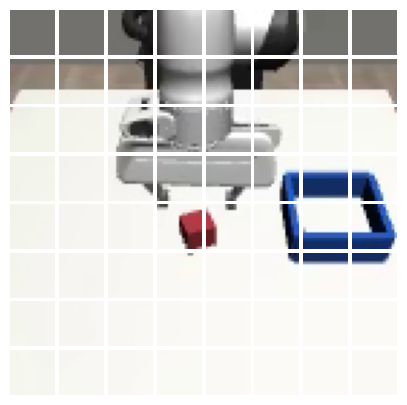

In [10]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(8, 8, figsize=(5, 5), gridspec_kw=dict(wspace=0.08, hspace=0.08))
for ax, patch in zip(axs.flat, patches):
    ax.imshow(patch.view(16, 16, 3).cpu())  # 768 numbers back to a 16 x 16 square
    ax.axis('off')
plt.show()

**What the 64 tokens hold:**

- **The cube spans ~2 patches** (row 5, cols 4-5), ~3% of the tokens. The grasp depends on those two plus the 3-4 patches with the gripper's fingers.
- **About half the patches are empty table**, the top row is background. Each still gets a full token and the same attention.
- **Patch edges cut through objects**: the gripper is split over ~10 patches, the cube straddles a border. Only the learned position vectors tell the model which patches are neighbours. (Verne patches VAE latents instead: each latent cell has already summarised its neighbourhood with convolutions.)


### box 1b: do the eyes matter? the same model with a blank (grey) frame

Step 0 scored 17/40 with the real frame (8/20 replanning every 8). If a grey frame scores about the same, the model drives from the joints.


In [11]:
import logging
import os

import torch

os.environ.setdefault('MUJOCO_GL', 'egl')
logging.disable(logging.WARNING)
import robosuite  # noqa: F401

logging.disable(logging.NOTSET)
logging.getLogger('robosuite_logs').setLevel(logging.ERROR)
from dream_robot.core.registry import make_env

env = make_env('robosuite/pick_place_cube')

In [12]:
def act(net: verne.model.Verne, obs, blank: bool) -> np.ndarray:
    # top frame (or grey, if blank) + joints -> [16, 8] raw actions
    frame = torch.from_numpy(obs.images['top']).permute(2, 0, 1)[None].cuda().float() / 127.5 - 1
    frame = torch.zeros_like(frame) if blank else frame  # 0 = mid-grey in [-1, 1]
    s = (torch.from_numpy(obs.state)[None].cuda() - demos.s_mean) / demos.s_std
    chunk = (verne.model.sample(net, frame, s) * demos.a_std + demos.a_mean)[0].cpu().numpy()
    chunk[:, 7] = np.clip(chunk[:, 7], 0.0, 1.0)
    return chunk


def rollout(net: verne.model.Verne, seed: int, n_exec: int, blank: bool) -> tuple[bool, str, int]:
    obs, plan = env.reset(seed=seed), []
    for step in range(600):
        if not plan:
            plan = list(act(net, obs, blank)[:n_exec])
        r = env.step(plan.pop(0))
        obs = r.observation
        if r.terminated or r.truncated:
            break
    return r.success, str(r.failure_mode), step + 1

In [13]:
from collections import Counter


@cache
def sweep(n_exec: int, blank: bool) -> dict[int, tuple[bool, str, int]]:
    net = verne.model.Verne().cuda().eval()
    net.load_state_dict(weights)
    torch.manual_seed(n_exec)
    res = {seed: rollout(net, seed, n_exec, blank) for seed in range(1000, 1020)}
    fails = Counter(mode for ok, mode, _ in res.values() if not ok)
    print(f'blank {blank}: {sum(ok for ok, _, _ in res.values()):2d}/20   failures {dict(fails)}')
    return res

sweep: cached, 1 call(s) stored


In [14]:
blank_run = sweep(8, blank=True)
print('real frame (step 0): 8/20')

blank True:  0/20   failures {'no_grasp': 20}
real frame (step 0): 8/20


**Grey frame: 0/20, all no_grasp** (real frame 8/20). The model can't act on a flat grey frame. Box 2b shows why it is _not_ that the cube is found in the image: erasing only the cube costs nothing (9/20). A grey frame is simply far outside what it trained on.


### box 2: what the action tokens look at

In each action layer, the 16 action tokens attend over 81 keys: the 65 video tokens of the paired video layer (joints token + 64 patches) and the 16 action tokens. `attention` is `velocity()` with the softmax weights written out (`F.scaled_dot_product_attention` doesn't return them), averaged over the 4 heads. It's taken at the last flow step (τ = 0.9) on the chunk the model samples for the frame from box 1.


In [15]:
net = verne.model.Verne().cuda().eval()
net.load_state_dict(weights)


@torch.no_grad()
def attention(net: verne.model.Verne, frame, state, x, tau) -> torch.Tensor:
    # out [B, LAYERS, 16, 81]: each action token's weights on [65 video keys, 16 action keys]
    kvs = net.see(frame, state)
    y = net.action_in(x) + net.action_pos + net.time_in(tau[:, None])[:, None]
    maps = []
    for block, (k_video, v_video) in zip(net.action, kvs):
        q, k, v = block.qkv_of(y)
        k, v = torch.cat([k_video, k], 2), torch.cat([v_video, v], 2)
        maps.append((q @ k.transpose(-1, -2) / q.shape[-1] ** 0.5).softmax(-1).mean(1))
        y = block.finish(y, q, k, v)
    return torch.stack(maps, 1)

In [16]:
frame = demos.top[row][None].float() / 127.5 - 1
state = (demos.state[row][None] - demos.s_mean) / demos.s_std
torch.manual_seed(0)
x = verne.model.sample(net, frame, state)
attn = attention(net, frame, state, x, torch.full((1,), 0.9, device='cuda'))[0]  # [4, 16, 81]
cube = [1 + 4 * 8 + 3, 1 + 4 * 8 + 4]  # row 5, cols 4-5 of the grid; +1 for the joints token
for layer, a in enumerate(attn.mean(1)):  # averaged over the 16 action tokens
    print(
        f'layer {layer}: video {a[:65].sum():.2f}  joints {a[0]:.2f}  cube 2 patches {a[cube].sum():.2f}  '
        f'actions {a[65:].sum():.2f}'
    )
print(f'if spread evenly: cube 2 patches {2 / 81:.2f}')

layer 0: video 0.93  joints 0.22  cube 2 patches 0.02  actions 0.07
layer 1: video 0.66  joints 0.28  cube 2 patches 0.01  actions 0.34
layer 2: video 0.60  joints 0.24  cube 2 patches 0.01  actions 0.40
layer 3: video 0.54  joints 0.10  cube 2 patches 0.01  actions 0.46
if spread evenly: cube 2 patches 0.02


**The cube patches get no more attention than chance** (0.01-0.02, even spread 0.02), in every layer. One frame, one sample.

- **Video keys take most of it**: 0.93 in layer 0, falling to 0.54 in layer 3, while attention to the other action tokens rises 0.07 → 0.46 (later layers shape the chunk itself).
- **The joints token alone takes 0.10-0.28**, 10× an average patch.
- This doesn't mean the cube is ignored: from layer 1 on, a video key is a token after attention, so cube information can sit in _any_ patch's token. Only layer 0's keys are the raw patches, and there the cube is at chance too. The grey-frame 0/20 says the image is used; the next plot shows where the weight goes instead.


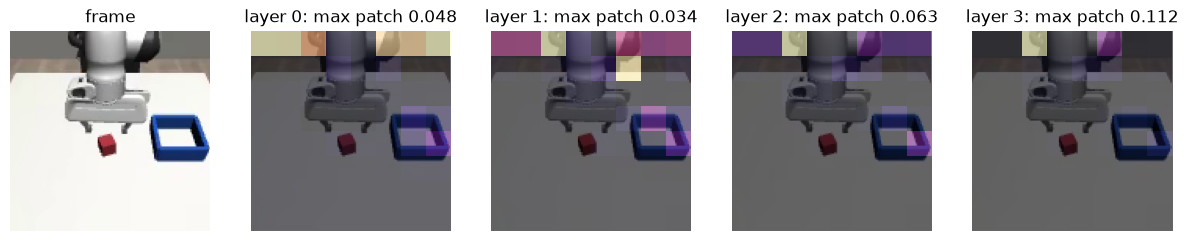

In [17]:
fig, axs = plt.subplots(1, 5, figsize=(15, 3.3))
axs[0].imshow(demos.top[row].permute(1, 2, 0).cpu())
axs[0].set_title('frame')
for layer, ax in enumerate(axs[1:]):
    heat = attn[layer].mean(0)[1:65].view(8, 8).cpu()  # the 64 patches, joints token left out
    ax.imshow(demos.top[row].permute(1, 2, 0).cpu())
    ax.imshow(heat, extent=(0, 128, 128, 0), cmap='magma', alpha=0.6)
    ax.set_title(f'layer {layer}: max patch {heat.max():.3f}')
for ax in axs:
    ax.axis('off')
plt.show()

**The weight goes to the top row and the bin's edge, not the cube or the gripper.** Brighter = more attention, averaged over the 16 action tokens.

- **Top row** (grey background and the arm's base, the same in every frame): the brightest patches in every layer. Layer 3's top patch takes 0.11, 7× an even share (1/81 ≈ 0.012).
- **The bin's right edge** lights up in layers 0-2. The bin never moves either.
- **Cube, fingers, table: dark.**
- A known transformer habit: patches that carry no information of their own get used as scratch space ("registers", Darcet et al. 2023). The video layers write a summary of the scene into them, and the action tokens read it there. If so, the cube is seen _through_ the top-row tokens, which is why the grey frame still breaks everything. One frame, one sample: a guess to test, not a finding yet.


### box 2b: is the scene read through the top row?

Two separate tests:

- **cube erased**: every patch with a red pixel (found in the image each step, so it follows the cube) is painted table colour. Tests whether the cube's own pixels are needed.
- **top row blocked** (next): the action tokens may not attend to the 8 top-row video tokens. Greying those patches wouldn't test it: a scratch token is used for its _position_, it holds the summary whatever its pixels show.


In [18]:
def erase_cube(frame: torch.Tensor) -> torch.Tensor:
    # frame [B, 3, 128, 128] in [-1, 1] -> every 16 x 16 patch with a red pixel painted table colour
    r, g, b = frame[:, 0], frame[:, 1], frame[:, 2]
    red = (r > 0.2) & (g < -0.3) & (b < -0.3)  # [B, 128, 128]
    hit = red.view(-1, 8, 16, 8, 16).any(4).any(2)  # [B, 8, 8]
    hit = hit.repeat_interleave(16, 1).repeat_interleave(16, 2)[:, None]  # [B, 1, 128, 128]
    table = frame[..., 112:, :16].mean((-1, -2), keepdim=True)  # bottom-left corner: table
    return torch.where(hit, table, frame)

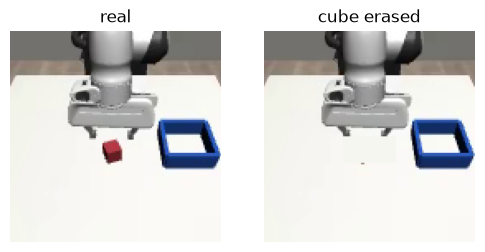

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(6, 3.2))
for ax, shown, name in zip(axs, [frame, erase_cube(frame)], ['real', 'cube erased']):
    ax.imshow(((shown[0].permute(1, 2, 0) + 1) / 2).clamp(0, 1).cpu())
    ax.set_title(name)
    ax.axis('off')
plt.show()

**The cube is gone, nothing else changes much.** The erased block is 1 × 3 patches (the cube straddles a border), so it also takes the tips of the fingers above it. The table colour leaves only a faint seam.


`sample_blocked` is `sample()` with the action layers written out, so the attention can take a mask: the action tokens may not attend to the `blocked` video tokens (token 0 = joints, 1-64 = patches row by row). As a control, the **bottom row** (empty table) is blocked the same way: if blocking any 8 patches hurts, the top row isn't special.


In [20]:
import torch.nn.functional as F


@torch.no_grad()
def sample_blocked(net: verne.model.Verne, frame, state, blocked: list[int], steps: int = 10):
    kvs = net.see(frame, state)
    allow = torch.ones(65 + 16, dtype=torch.bool, device='cuda')
    allow[blocked] = False  # keys the action tokens can't see
    x = torch.randn(len(frame), 16, 8, device='cuda')
    for i in range(steps):
        tau = torch.full((len(frame),), i / steps, device='cuda')
        y = net.action_in(x) + net.action_pos + net.time_in(tau[:, None])[:, None]
        for block, (k_video, v_video) in zip(net.action, kvs):
            q, k, v = block.qkv_of(y)
            k, v = torch.cat([k_video, k], 2), torch.cat([v_video, v], 2)
            a = F.scaled_dot_product_attention(q, k, v, attn_mask=allow)  # Block.finish, masked
            y = y + block.out(a.transpose(1, 2).flatten(2))
            y = y + block.mlp(block.norm2(y))
        x = x + net.action_out(y) / steps
    return x

In [21]:
TOP, BOTTOM = list(range(1, 9)), list(range(57, 65))  # patch rows 1 and 8


def act_edit(net: verne.model.Verne, obs, which: str) -> np.ndarray:
    # which: 'erase' (cube painted out), 'block top' or 'block bottom'
    frame = torch.from_numpy(obs.images['top']).permute(2, 0, 1)[None].cuda().float() / 127.5 - 1
    s = (torch.from_numpy(obs.state)[None].cuda() - demos.s_mean) / demos.s_std
    if which == 'erase':
        x = verne.model.sample(net, erase_cube(frame), s)
    else:
        x = sample_blocked(net, frame, s, TOP if which == 'block top' else BOTTOM)
    chunk = (x * demos.a_std + demos.a_mean)[0].cpu().numpy()
    chunk[:, 7] = np.clip(chunk[:, 7], 0.0, 1.0)
    return chunk


def rollout_edit(
    net: verne.model.Verne, seed: int, n_exec: int, which: str
) -> tuple[bool, str, int]:
    obs, plan = env.reset(seed=seed), []
    for step in range(600):
        if not plan:
            plan = list(act_edit(net, obs, which)[:n_exec])
        r = env.step(plan.pop(0))
        obs = r.observation
        if r.terminated or r.truncated:
            break
    return r.success, str(r.failure_mode), step + 1

In [22]:
@cache
def sweep_edit(n_exec: int, which: str) -> dict[int, tuple[bool, str, int]]:
    torch.manual_seed(n_exec)
    res = {seed: rollout_edit(net, seed, n_exec, which) for seed in range(1000, 1020)}
    fails = Counter(mode for ok, mode, _ in res.values() if not ok)
    print(f'{which:12s}: {sum(ok for ok, _, _ in res.values()):2d}/20   failures {dict(fails)}')
    return res

sweep_edit: cached, 3 call(s) stored


In [23]:
edits = {which: sweep_edit(8, which) for which in ['erase', 'block top', 'block bottom']}
print('real frame: 8/20   grey frame: 0/20')

erase       :  9/20   failures {'no_grasp': 10, 'wrong_target': 1}
block top   :  9/20   failures {'no_grasp': 9, 'wrong_target': 2}
block bottom:  7/20   failures {'no_grasp': 11, 'dropped': 1, 'wrong_target': 1}
real frame: 8/20   grey frame: 0/20


**Neither the cube's pixels nor the top row matter: cube erased 9/20, top row blocked 9/20, bottom row blocked 7/20** (real frame 8/20). Checked: the erase finds the cube in sim frames (46-54 red pixels, 2-4 patches repainted), and `sample_blocked` with nothing blocked equals `sample` exactly.

- **T1 places the cube within ±3 cm of one spot** (`cube_xy_range: [0.03, 0.03]` in `task.yaml`). The model doesn't locate the cube: it reaches for the average spot, and that grasp works about half the time. That is the ~8/20.
- **So the grey frame's 0/20 was not "no cube information"**: a flat grey image is far outside anything it trained on, and that breaks it. What the real image does give it is still open: likely where the arm is and which phase it's in (reach, grasp, carry).
- The register guess from the heatmap is wrong: blocking the top row costs nothing.


## T1-wide: a T1 where the eyes have to find the cube

Same scene and expert, but the cube spawns over x [−10, +10] cm, y [−10, +6] cm instead of ±3 cm (the bin side stops at +6: closer, the open fingers land on the bin's wall). 100 expert demos, 100% success (`data/robosuite/pick_place_cube_wide_n100`). Reaching for the average spot now misses by more than a gripper's width, so the score should depend on seeing the cube.

Everything below trains on **90 demos** (10 held out): with 10 demos spread over 20 × 16 cm, the model could fail everywhere and tell us nothing.


In [24]:
WIDE = 'pick_place_cube_wide_n100'


@cache
def table_wide():
    state, action, episode = load_table(WIDE)  # [N, 8], [N, 8], [N]
    return frozendict(state=state, action=action, episode=episode)

table_wide: cached, 1 call(s) stored


In [25]:
@cache
def images_wide():
    return load_top(WIDE)  # [N, 3, 128, 128] uint8, a few minutes the first time

images_wide: cached, 1 call(s) stored


In [26]:
val = np.random.default_rng(0).permutation(100)[:10]
w_data = table_wide()
w_split = frozendict(val=val, train=np.setdiff1d(np.arange(100), val))
w_demos = to_gpu(
    images_wide(), w_data['state'], w_data['action'], w_data['episode'], w_split['train']
)
print({k: len(v) for k, v in w_split.items()}, tuple(w_demos.top.shape))

{'val': 10, 'train': 90} (22409, 3, 128, 128)


### T1-wide: train the step 0 model on 90 demos (20k steps, ~3 min)


In [27]:
@cache
def train_wide(steps: int):
    return verne.train.train(w_demos, w_split['train'], w_split['val'], steps)

train_wide: cached, 1 call(s) stored


In [28]:
w_weights, w_log = train_wide(20000)

step      0   train 2.087   val 2.870
step   1000   train 0.194   val 0.134
step   2000   train 0.073   val 0.090
step   3000   train 0.103   val 0.095
step   4000   train 0.045   val 0.081
step   5000   train 0.060   val 0.072
step   6000   train 0.080   val 0.079
step   7000   train 0.038   val 0.063
step   8000   train 0.049   val 0.070
step   9000   train 0.023   val 0.059
step  10000   train 0.047   val 0.072
step  11000   train 0.042   val 0.061
step  12000   train 0.044   val 0.054
step  13000   train 0.044   val 0.069
step  14000   train 0.054   val 0.052
step  15000   train 0.039   val 0.053
step  16000   train 0.039   val 0.050
step  17000   train 0.027   val 0.058
step  18000   train 0.027   val 0.049
step  19000   train 0.047   val 0.053
step  20000   train 0.024   val 0.055


**Held-out loss ~0.05 at the end** (10 demos on T1: best 0.17, end 0.25). With 90 demos it no longer overfits.

### T1-wide rollouts: real frame vs cube erased

Seeds 1000-1019 in a sim built with the same spawn range. `erase` paints the cube's patches table colour (box 2b's `erase_cube`) on every frame the model sees.


In [29]:
from dataclasses import replace

from dream_robot.sims.robosuite.tasks.pick_place_cube.env import PickPlaceCube, TaskConfig

w_env = PickPlaceCube(replace(TaskConfig.load(), cube_xy_range=((-0.10, 0.10), (-0.10, 0.06))))
w_net = verne.model.Verne().cuda().eval()
w_net.load_state_dict(w_weights)

<All keys matched successfully>

In [30]:
def rollout_wide(seed: int, n_exec: int, erase: bool) -> tuple[bool, str, int]:
    obs, plan = w_env.reset(seed=seed), []
    for step in range(600):
        if not plan:
            frame = (
                torch.from_numpy(obs.images['top']).permute(2, 0, 1)[None].cuda().float() / 127.5
                - 1
            )
            frame = erase_cube(frame) if erase else frame
            s = (torch.from_numpy(obs.state)[None].cuda() - w_demos.s_mean) / w_demos.s_std
            x = verne.model.sample(w_net, frame, s)
            chunk = (x * w_demos.a_std + w_demos.a_mean)[0].cpu().numpy()
            chunk[:, 7] = np.clip(chunk[:, 7], 0.0, 1.0)
            plan = list(chunk[:n_exec])
        r = w_env.step(plan.pop(0))
        obs = r.observation
        if r.terminated or r.truncated:
            break
    return r.success, str(r.failure_mode), step + 1

In [31]:
@cache
def sweep_wide(n_exec: int, erase: bool) -> dict[int, tuple[bool, str, int]]:
    torch.manual_seed(n_exec)
    res = {seed: rollout_wide(seed, n_exec, erase) for seed in range(1000, 1020)}
    fails = Counter(mode for ok, mode, _ in res.values() if not ok)
    name = f'n_exec {n_exec:2d}' + (', cube erased' if erase else '')
    print(f'{name:24s}: {sum(ok for ok, _, _ in res.values()):2d}/20   failures {dict(fails)}')
    return res

sweep_wide: cached, 3 call(s) stored


In [32]:
w_sweeps = {(n, erase): sweep_wide(n, erase) for n, erase in [(8, False), (16, False), (8, True)]}

n_exec  8               :  1/20   failures {'no_grasp': 19}
n_exec 16               :  1/20   failures {'no_grasp': 19}
n_exec  8, cube erased  :  1/20   failures {'no_grasp': 18, 'dropped': 1}


**T1-wide: 1/20, 1/20, and 1/20 with the cube erased.** Almost every run is no_grasp, and seeing the cube makes no difference.

- The held-out loss was low (0.05), yet the closed loop fails: predicting the demo's next actions well offline doesn't put the fingers on the cube.
- Not yet ruled out: a mistake in the rollout path (sim built at the new range, stats from the wide demos). Next: the same model on spawns near the centre, and films of a few failures to see where the gripper goes relative to the cube.


In [33]:
import imageio
from IPython.display import Markdown, display

for seed in range(1000, 1004):  # n_exec 8, real frame; [top | wrist] at 20 fps
    obs, plan, frames = w_env.reset(seed=seed), [], []
    torch.manual_seed(seed)
    for step in range(400):
        frames.append(np.concatenate([obs.images['top'], obs.images['wrist']], axis=1))
        if not plan:
            frame = (
                torch.from_numpy(obs.images['top']).permute(2, 0, 1)[None].cuda().float() / 127.5
                - 1
            )
            s = (torch.from_numpy(obs.state)[None].cuda() - w_demos.s_mean) / w_demos.s_std
            chunk = (
                (verne.model.sample(w_net, frame, s) * w_demos.a_std + w_demos.a_mean)[0]
                .cpu()
                .numpy()
            )
            chunk[:, 7] = np.clip(chunk[:, 7], 0.0, 1.0)
            plan = list(chunk[:8])
        r = w_env.step(plan.pop(0))
        obs = r.observation
        if r.terminated or r.truncated:
            break
    path = f'../../scratch/wide_step0_seed{seed}_{"ok" if r.success else r.failure_mode}.mp4'
    imageio.mimsave(path, frames, fps=20)
    outcome = 'ok' if r.success else str(r.failure_mode)
    display(
        Markdown(f'seed {seed}: {outcome}, {len(frames)} steps → [{path.split("/")[-1]}]({path})')
    )

seed 1000: none, 400 steps → [wide_step0_seed1000_none.mp4](../../scratch/wide_step0_seed1000_none.mp4)

seed 1001: none, 400 steps → [wide_step0_seed1001_none.mp4](../../scratch/wide_step0_seed1001_none.mp4)

seed 1002: none, 400 steps → [wide_step0_seed1002_none.mp4](../../scratch/wide_step0_seed1002_none.mp4)

seed 1003: none, 400 steps → [wide_step0_seed1003_none.mp4](../../scratch/wide_step0_seed1003_none.mp4)

**Films (`scratch/wide_step0_seed100*.mp4`, [top | wrist], first 400 steps): it goes for the cube's side of the table, then misses by a few cm.**

- Seed 1000: the gripper comes down next to the cube (the cube is in the wrist view, beside the fingers), closes on nothing, hovers around the cube's area, briefly heads for the bin, comes back. Never gets it.
- Seed 1002: reaches over the cube's area, misses, then carries an empty gripper to the bin and parks over it, the WAMz-style "pretend it's in the hand".
- So the image does steer the reach roughly, but not to within a finger's width. Erasing the cube still scored 1/20, so how much of the rough steering comes from the cube itself is open.


**Box 3: where does it close?** For each wide rollout, the gripper's xy when it first commands close, against the cube's spawn xy.

- reach point doesn't move with the cube (slope ≈ 0) → blind: it reaches for the average spot.
- moves partway (0 < slope < 1) → it sees the cube, coarsely.
- slope ≈ 1 with a small offset → it sees it; the miss is precision.


In [34]:
def close_point(seed: int, n_exec: int) -> tuple[np.ndarray, np.ndarray | None]:
    # out: cube xy at spawn, gripper xy at the first commanded close (None if it never closes)
    obs, plan = w_env.reset(seed=seed), []
    cube = w_env.cube_pos[:2]
    for step in range(600):
        if not plan:
            frame = (
                torch.from_numpy(obs.images['top']).permute(2, 0, 1)[None].cuda().float() / 127.5
                - 1
            )
            s = (torch.from_numpy(obs.state)[None].cuda() - w_demos.s_mean) / w_demos.s_std
            x = verne.model.sample(w_net, frame, s)
            chunk = (x * w_demos.a_std + w_demos.a_mean)[0].cpu().numpy()
            chunk[:, 7] = np.clip(chunk[:, 7], 0.0, 1.0)
            plan = list(chunk[:n_exec])
        a = plan.pop(0)
        if a[7] < 0.5:
            return cube, np.asarray(w_env._raw['robot0_eef_pos'][:2], dtype=float).copy()
        r = w_env.step(a)
        obs = r.observation
        if r.terminated or r.truncated:
            break
    return cube, None

In [35]:
@cache
def close_points(n_exec: int) -> dict[int, tuple[np.ndarray, np.ndarray | None]]:
    torch.manual_seed(n_exec)
    return {seed: close_point(seed, n_exec) for seed in range(1000, 1020)}


pts = close_points(8)
print('seed   cube x, y (cm)    gripper x, y (cm)   miss (cm)')
for seed, (c, g) in pts.items():
    if g is None:
        print(f'{seed}   {c[0] * 100:6.1f} {c[1] * 100:6.1f}     never closes')
    else:
        print(
            f'{seed}   {c[0] * 100:6.1f} {c[1] * 100:6.1f}     {g[0] * 100:6.1f} {g[1] * 100:6.1f}      {np.linalg.norm(g - c) * 100:5.1f}'
        )

close_points: cached, 1 call(s) stored
seed   cube x, y (cm)    gripper x, y (cm)   miss (cm)
1000     -6.4    1.9       -7.6   -0.4        2.7
1001     -9.2   -2.2        6.8    2.9       16.8
1002      2.3   -1.2        5.9   -9.3        8.9
1003     -2.5   -7.1        9.4    0.4       14.1
1004     -1.5    0.5        8.6   -3.5       10.9
1005     -1.3    2.9        9.2   -6.5       14.1
1006     -4.9   -6.2        5.6   -3.4       10.8
1007     -6.6   -5.4        7.0   -4.5       13.6
1008     -5.6    3.4        8.2   -7.8       17.7
1009      3.9   -9.9        5.4    1.5       11.6
1010     -1.3    3.2       -5.9    0.5        5.4
1011      3.3   -3.0        9.2    4.1        9.3
1012     -2.1    2.8       -4.6    0.5        3.4
1013      9.1   -6.0       -3.5   -3.8       12.8
1014     -3.1   -8.5        4.4   -5.8        7.9
1015     -9.0    5.2        7.3    4.2       16.3
1016      6.0   -5.0        9.1   -2.4        4.1
1017     -7.4    1.5        8.7   -1.3       16.3
1018  

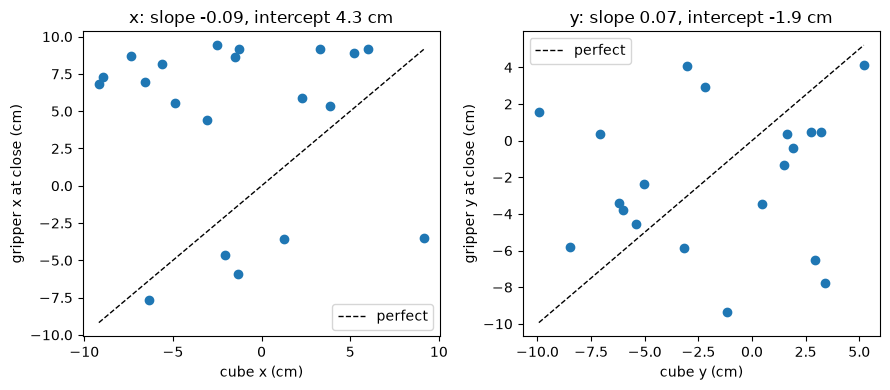

In [36]:
import matplotlib.pyplot as plt

done = [(c, g) for c, g in pts.values() if g is not None]
C, G = np.array([c for c, _ in done]), np.array([g for _, g in done])
fig, axs = plt.subplots(1, 2, figsize=(9, 4))
for k, (ax, name) in enumerate(zip(axs, 'xy')):
    slope, icpt = np.polyfit(C[:, k], G[:, k], 1)
    ax.scatter(C[:, k] * 100, G[:, k] * 100)
    lim = np.array([C[:, k].min(), C[:, k].max()]) * 100
    ax.plot(lim, lim, 'k--', lw=1, label='perfect')
    ax.set(
        xlabel=f'cube {name} (cm)',
        ylabel=f'gripper {name} at close (cm)',
        title=f'{name}: slope {slope:.2f}, intercept {icpt * 100:.1f} cm',
    )
    ax.legend()
fig.tight_layout()

In [37]:
from dream_robot.sims.robosuite.tasks.pick_place_cube.expert import ExpertPolicy

expert = ExpertPolicy(w_env)
for seed in range(1000, 1005):  # check: the expert's close point should sit on the cube
    obs = w_env.reset(seed=seed)
    expert.reset()
    cube = w_env.cube_pos[:2]
    for _ in range(600):
        a, _ = expert(obs)
        if a[7] < 0.5:
            g = np.asarray(w_env._raw['robot0_eef_pos'][:2], dtype=float)
            print(
                f'{seed}  cube {cube * 100}  gripper {g * 100}  miss {np.linalg.norm(g - cube) * 100:.1f} cm'
            )
            break
        obs = w_env.step(a).observation

1000  cube [-6.3548696   1.89663063]  gripper [-6.29883799  1.8930737 ]  miss 0.1 cm
1001  cube [-9.17738927 -2.189209  ]  gripper [-9.0748241  -2.19210839]  miss 0.1 cm
1002  cube [ 2.29031611 -1.1795154 ]  gripper [ 2.20696637 -1.18034984]  miss 0.1 cm
1003  cube [-2.53749908 -7.0829953 ]  gripper [-2.51096624 -7.0799031 ]  miss 0.0 cm
1004  cube [-1.48303981  0.47876541]  gripper [-1.49429578  0.47459042]  miss 0.0 cm


**Box 3 result: blind.** Where the gripper closes doesn't depend on where the cube is: slope x −0.09, y +0.07, correlation ≈ 0.08. The average miss is ~10 cm, not "a few cm".

- The close points fall in two clumps, whatever the cube does: x ≈ +4..+9 cm (14/20) or x ≈ −4..−8 cm (6/20). The model picks a remembered grasp spot, not the cube.
- Measurement check: the expert's close point sits within 0.1 cm of the cube (5 seeds), so the frames and the logging are right.
- So the coarse-vision story is out: the top camera's cube patches aren't being used at all. The wrist camera alone may not fix this; the model first has to learn to read the cube from some view.
